In [6]:
import os
from prepare_data import process_all_folds

# Using the Fold 5 training file as a sentinel to check if the data preparation has already run
file_sentinel = "data/MSLR-WEB10K/Fold5/train_clean.txt"

if not os.path.exists(file_sentinel):
    print("Clean data not found. Starting extraction from raw SVM-Rank files...")
    process_all_folds(base_dataset_dir="data/MSLR-WEB10K", num_folds=5)
else:
    print("Data already formatted and ready for training. Data preparation step skipped.")

Data already formatted and ready for training. Data preparation step skipped.


In [7]:
import multiprocessing as mp
from utils import run_experiment

# experiments configuration
experiments = [
    {"name": "Baseline (GBDT no EFB)", "use_goss": False, "use_efb": False},
    {"name": "Solo EFB", "use_goss": False, "use_efb": True},
    {"name": "Solo GOSS", "use_goss": True, "use_efb": False},
    {"name": "LightGBM (GOSS + EFB)", "use_goss": True, "use_efb": True},
]

# get a fresh OS process context for isolation
context = mp.get_context('spawn')

# create a manager for shared data between processes
manager = context.Manager()
results_dict = manager.dict()

for conf in experiments:
    # create a new OS-level process for the experiment
    p = context.Process(
        target=run_experiment, 
        args=(conf["name"], conf["use_goss"], conf["use_efb"], results_dict)
    )
    
    p.start() 
    p.join()  
    
    # OS-level integrity check
    if p.exitcode != 0:
        print(f"Attention: The experiment '{conf['name']}' failed with OS code {p.exitcode}.")
    else:
        print(f"--- Process for '{conf['name']}' closed successfully. ---\n")

final_results = dict(results_dict)
print("\nTraining finished")


Start experiment: Baseline (GBDT no EFB)
[LightGBM] [Info] Calculating query boundaries...
[LightGBM] [Info] Construct bin mappers from text data time 0.99 seconds
[200]	valid's ndcg@1: 0.493824	valid's ndcg@3: 0.483009	valid's ndcg@5: 0.488243	valid's ndcg@10: 0.507159	test's ndcg@1: 0.488681	test's ndcg@3: 0.480484	test's ndcg@5: 0.487904	test's ndcg@10: 0.504761
[400]	valid's ndcg@1: 0.497524	valid's ndcg@3: 0.483577	valid's ndcg@5: 0.489917	valid's ndcg@10: 0.508278	test's ndcg@1: 0.486748	test's ndcg@3: 0.484474	test's ndcg@5: 0.490159	test's ndcg@10: 0.507503
[600]	valid's ndcg@1: 0.498552	valid's ndcg@3: 0.483051	valid's ndcg@5: 0.490465	valid's ndcg@10: 0.507651	test's ndcg@1: 0.492162	test's ndcg@3: 0.483992	test's ndcg@5: 0.488754	test's ndcg@10: 0.507681
[800]	valid's ndcg@1: 0.495143	valid's ndcg@3: 0.480916	valid's ndcg@5: 0.489893	valid's ndcg@10: 0.506818	test's ndcg@1: 0.487171	test's ndcg@3: 0.481662	test's ndcg@5: 0.486479	test's ndcg@10: 0.506606
[1000]	valid's ndcg

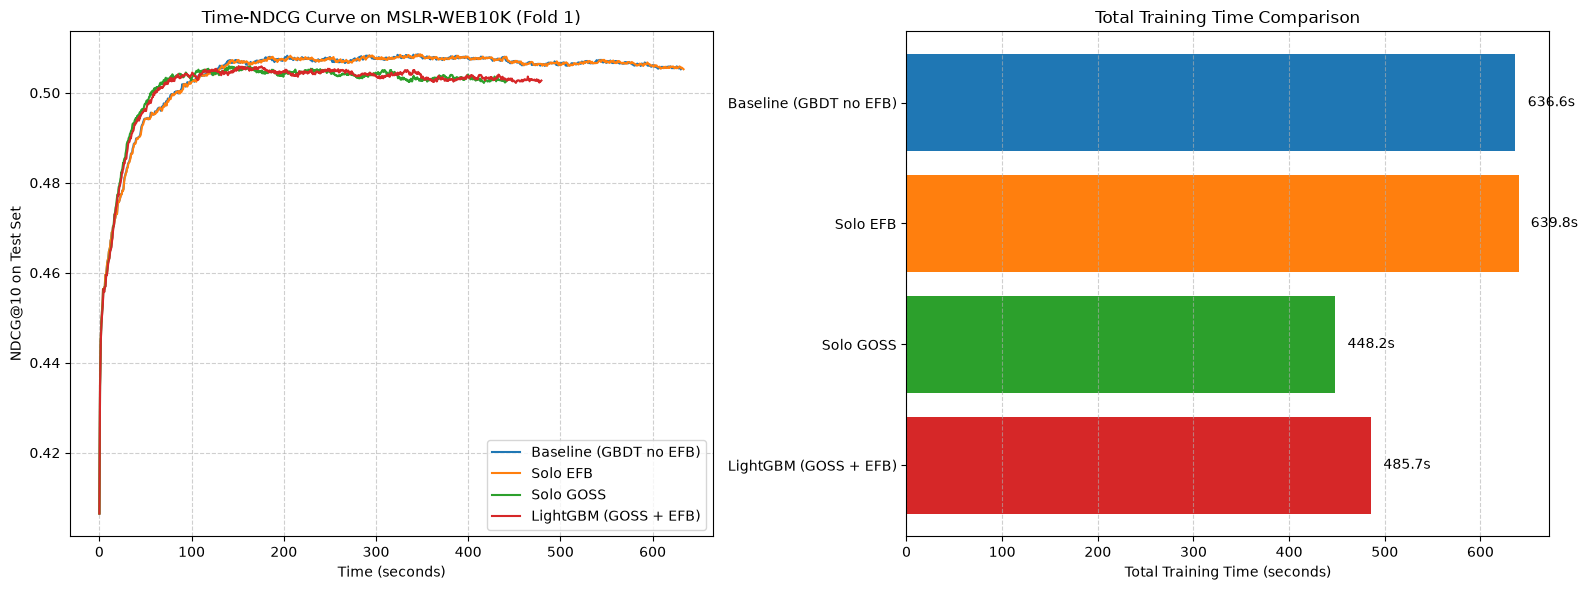

In [10]:
import matplotlib.pyplot as plt
import numpy as np

experiment_names = list(final_results.keys())
times = [final_results[name]["time"] for name in experiment_names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# GRAPH 1: Time-NDCG Curve (Come nel paper originale)
for name in experiment_names:
    ndcg_history = final_results[name]["ndcg_history"]
    time_history = final_results[name]["time_history"]
    
    # Asse X: Tempo cumulativo in secondi, Asse Y: NDCG@10
    ax1.plot(time_history, ndcg_history, label=name, linewidth=1.5)

ax1.set_title("Time-NDCG Curve on MSLR-WEB10K (Fold 1)")
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("NDCG@10 on Test Set")
ax1.legend(loc="lower right")
ax1.grid(True, linestyle='--', alpha=0.6)


# GRAPH 2: Training Time Comparison 
y_pos = np.arange(len(experiment_names))
bars = ax2.barh(y_pos, times, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax2.set_yticks(y_pos)
ax2.set_yticklabels(experiment_names)
ax2.invert_yaxis()
ax2.set_xlabel("Total Training Time (seconds)")
ax2.set_title("Total Training Time Comparison")
ax2.grid(True, axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    width = bar.get_width()
    ax2.text(width + max(times)*0.02, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}s', ha='left', va='center')

plt.tight_layout()
plt.show()